# Day 17

### ANN

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import History
from matplotlib import pyplot as plt

In [4]:
df = pd.read_csv(("../Day 13/Boston.csv"))

x = df.iloc[:,1:14]
y = df['medv']

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state = 2)

y_train = y_train.values
y_test = y_test.values

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
# Build the ANN model
model = Sequential()

model.add(Dense(6,activation='relu',kernel_initializer='uniform',input_shape=(X_train_scaled.shape[1],)))# First hidden layer
# model.add(Droput=0.1)
model.add(Dense(6, activation='relu',kernel_initializer = 'uniform'))  # Second hidden layer
model.add(Dense(1, activation='relu', kernel_initializer = 'uniform'))  # Output layer

In [22]:
# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mse'])

In [23]:
# Train the model and capture the training history
history = model.fit(X_train_scaled, y_train, epochs=500, batch_size=32, validation_split=0.2)

Epoch 1/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 601.6639 - mse: 601.6639 - val_loss: 532.9333 - val_mse: 532.9333
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 601.0496 - mse: 601.0496 - val_loss: 532.2939 - val_mse: 532.2939
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 600.3393 - mse: 600.3393 - val_loss: 531.5016 - val_mse: 531.5016
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 599.4326 - mse: 599.4326 - val_loss: 530.4721 - val_mse: 530.4721
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 598.2451 - mse: 598.2451 - val_loss: 529.0659 - val_mse: 529.0659
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 596.5760 - mse: 596.5760 - val_loss: 527.1069 - val_mse: 527.1069
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 594.3021 - mse: 594.3021 - val_loss: 524.4460 - val_mse: 524.4460
Epoch 8/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 591.2994 - mse: 591.2994 - val_loss: 520.9401 - val_mse: 520.9401

In [26]:
# Make predictions on the test set
predictions = model.predict(X_test_scaled)
pred = model.predict(X_test_scaled)
predictions = (predictions > 0.5).astype(int)  # Convert probabilities to binary predictions
from sklearn.metrics import mean_squared_error
err = np.sqrt(mean_squared_error(y_test, pred))
pd.crosstab(y_test, predictions.reshape(1,-1))
X_test_scaled.shape

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


(102, 13)

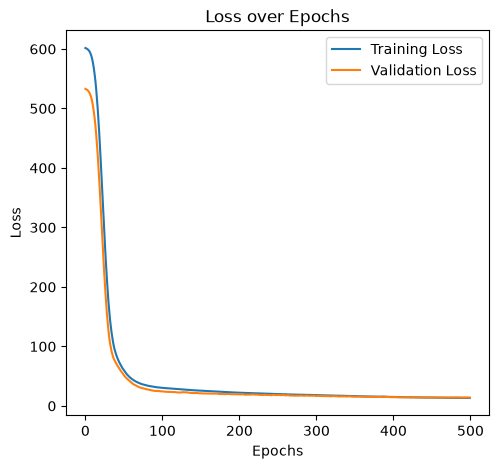

In [30]:
# Plot the training and validation loss
plt.figure(figsize=(12, 5))

# Plot for Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

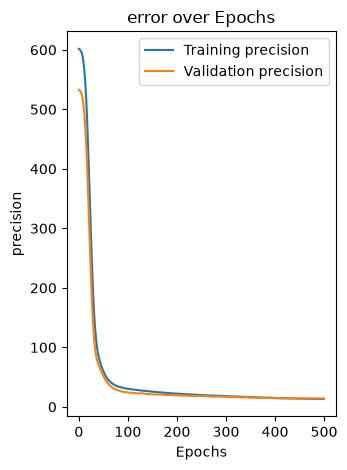

In [31]:
# Plot for Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['mse'], label='Training precision')
plt.plot(history.history['val_mse'], label='Validation precision')
plt.title('error over Epochs')
plt.xlabel('Epochs')
plt.ylabel('precision')
plt.legend()

plt.tight_layout()
plt.show()

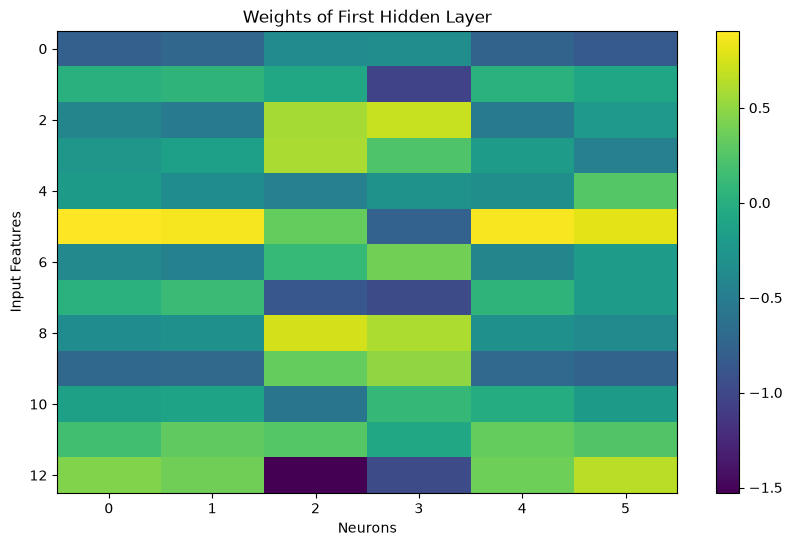

Model training complete and results visualized.


In [32]:
# Visualize the weights of the first hidden layer
weights, biases = model.layers[0].get_weights()
plt.figure(figsize=(10, 6))
plt.imshow(weights, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title('Weights of First Hidden Layer')
plt.xlabel('Neurons')
plt.ylabel('Input Features')
plt.show()

print("Model training complete and results visualized.")